In [49]:
import kagglehub
import heapq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import euclidean_distances, cosine_similarity
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [50]:
#create test data 
d = set(np.random.uniform(-1, 1, 10))
d = np.array(list(d))
print(d)

[-0.63319098 -0.39151551 -0.13610996 -0.41754172  0.04951286  0.22370579
 -0.72101228 -0.4157107  -0.26727631 -0.08786003]


In [51]:
# similarity matrix concerning languages as given on the WS 
sim_mat = np.array([
    [10, 6, 0, 0, 0, 0, 0, 0, 0],
    [6, 10, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 10, 5, 3, 3, 1, 1, 0],
    [0, 0, 5, 10, 1, 2, 1, 1, 0],
    [0, 0, 3, 1, 10, 4, 1, 2, 0],
    [0, 0, 3, 2, 4, 10, 1, 4, 0],
    [0, 0, 1, 1, 1, 1, 10, 1, 0],
    [0, 0, 1, 1, 2, 4, 1, 10, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 10]
])


Algorithm 1: Agglomerative hierarchical clustering algorithm

In [52]:
def find_best_pair(P, I, N):
    best_i = best_j = -1
    best_sim = -np.inf
    for i in range(N):
        if not I[i]:
            continue
        while P[i] and not I[P[i][0][1]]:
            heapq.heappop(P[i])
        if not P[i]:
            continue
        sim, j = P[i][0]
        sim = -sim
        if sim > best_sim:
            best_sim = sim
            best_i, best_j = i, j
    return best_i, best_j, best_sim

def new_similarity(sim_mat, i, j, k, linkage, cluster_sizes):
    sim_ij = sim_mat[i, j]
    sim_ik = sim_mat[i, k]

    if linkage == 'single':
        return max(sim_ij, sim_ik)

    elif linkage == 'complete':
        return min(sim_ij, sim_ik)

    elif linkage == 'average':
        Nj = cluster_sizes[j]
        Nk = cluster_sizes[k]

        if Nj + Nk == 0: return 0
        return (Nj * sim_ij + Nk * sim_ik) / (Nj + Nk)

    else:
        raise ValueError("Unknown linkage type: {}. Choose from 'single', 'complete', 'average'.".format(linkage))

# Here the first version of the Algo1 as written on the worksheet is implemented
def Algo1_single_linkage(d = None, S = None, linkage='single'):
    if d is not None:
        N = len(d)
        I = np.ones_like(d) # Indicator of active classes
        # computation of Sim matrix
        S = np.zeros([N,N]) #initialicing Sim. Matrix
        for i in range(N):
            for j in range(N):
                S[i,j] = - abs(d[i]-d[j])
    else: 
        N = len(S[0])
        I = np.ones_like(S[0]) # Indicator of active classes


    P = [[] for _ in range(N)]
    for i in range(N):
        for j in range(N):
            if i != j:
                # heapq is a min-heap, so we push negative similarities
                # to simulate a max-heap
                heapq.heappush(P[i], (-S[i, j], j))
    L = []
    cluster_sizes = np.ones(N, dtype=int)

    for k in range(N-1):

        iota_1, iota_2, best_sim = find_best_pair(P, I, N) # find the best pair to merge
        L.append([iota_1, iota_2, best_sim]) # record the merge
        if linkage == 'average':
            cluster_sizes[iota_1] += cluster_sizes[iota_2] # update cluster size
        I[iota_2] = 0  # mark iota_2 as inactive

        # suppress elements here
        for i in range(N):
            if not I[i] or i == iota_1:
                continue
            new_sim = new_similarity(S, i, iota_1, iota_2, linkage, cluster_sizes)
            S[iota_1, i] = new_sim
            S[i, iota_1] = new_sim

            heapq.heappush(P[iota_1], (-new_sim, i))
            heapq.heappush(P[i], (-new_sim, iota_1))

    return L

In [53]:
# test the algo1 function as a method 
result = Algo1_single_linkage(d = d)
print("Fusion List L:")
for merge in result:
    print(merge)

Fusion List L:
[3, 7, np.float64(-0.0018310166743524814)]
[1, 3, np.float64(-0.024195188848639138)]
[2, 9, np.float64(-0.04824993114984033)]
[0, 6, np.float64(-0.08782129840278396)]
[1, 8, np.float64(-0.12423920066830796)]
[1, 2, np.float64(-0.13116635069684812)]
[1, 4, np.float64(-0.13737289483040382)]
[1, 5, np.float64(-0.17419292618028326)]
[0, 1, np.float64(-0.2156492606892162)]


In [54]:
def convertToScypi(L, N, maxSim):
    Z = []
    cluster_id = N
    cluster_map = {i: i for i in range(N)}

    for merge in L:
        i1, i2, sim = merge
        c1 = cluster_map[i1]
        c2 = cluster_map[i2]
        dist = maxSim - sim
        if c1 < N:
            c1_size = 1
        else:
            c1_size = Z[c1 - N][3]
        
        if c2 < N:
            c2_size = 1
        else:
            c2_size = Z[c2 - N][3]

        newCluster_size = c1_size + c2_size

        if c1 < c2: # here I changed i1 <-- c1 and i2 <-- c2 ==> this was the key to optain the same visualization of dendrogram 
            Z.append([float(c1), float(c2), float(dist), float(newCluster_size)])
        else:
            Z.append([float(c2), float(c1), float(dist), float(newCluster_size)])
        cluster_map[i1] = cluster_id
        for key in cluster_map:
            if cluster_map[key] == c2:
                cluster_map[key] = cluster_id
        cluster_id += 1
    return np.array(Z)

In [55]:
def plot_dendrogram(Z, fig_size=(10,7), title='Dendrogram', xlabel='Samples', ylabel='Distance', save_as_png=False):
    plt.figure(figsize=fig_size)
    sch.dendrogram(Z)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    if save_as_png:
        plt.savefig('{}_Algo1.png'.format(title))
    plt.show()

# Dendrogram visualization

Test the given matrix with our Algo1 and scipy's dendrogram

Fusion List L:
[0, 1, np.int64(6)]
[2, 3, np.int64(5)]
[4, 5, np.int64(4)]
[4, 7, np.int64(4)]
[2, 4, np.int64(3)]
[2, 6, np.int64(1)]
[0, 2, np.int64(0)]
[0, 8, np.int64(0)]


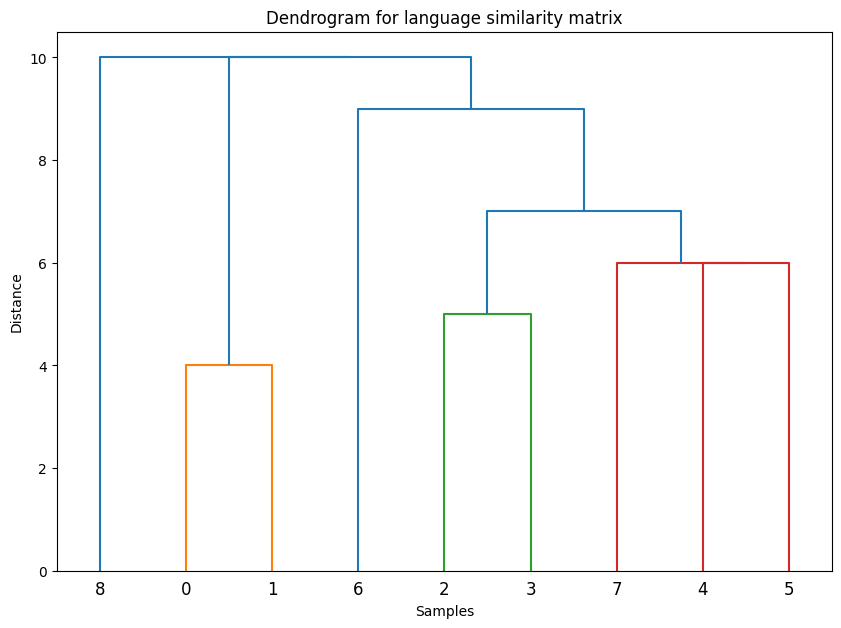

In [56]:
res_for_sim_mat = Algo1_single_linkage(S=sim_mat)

print("Fusion List L:")
for merge in res_for_sim_mat:
    print(merge)

Z = convertToScypi(res_for_sim_mat, sim_mat.shape[0], np.max(sim_mat))
plot_dendrogram(Z, fig_size=(10,7), title='Dendrogram for language similarity matrix', save_as_png=True)

Test with Mall_Customers dataset (from [Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python))

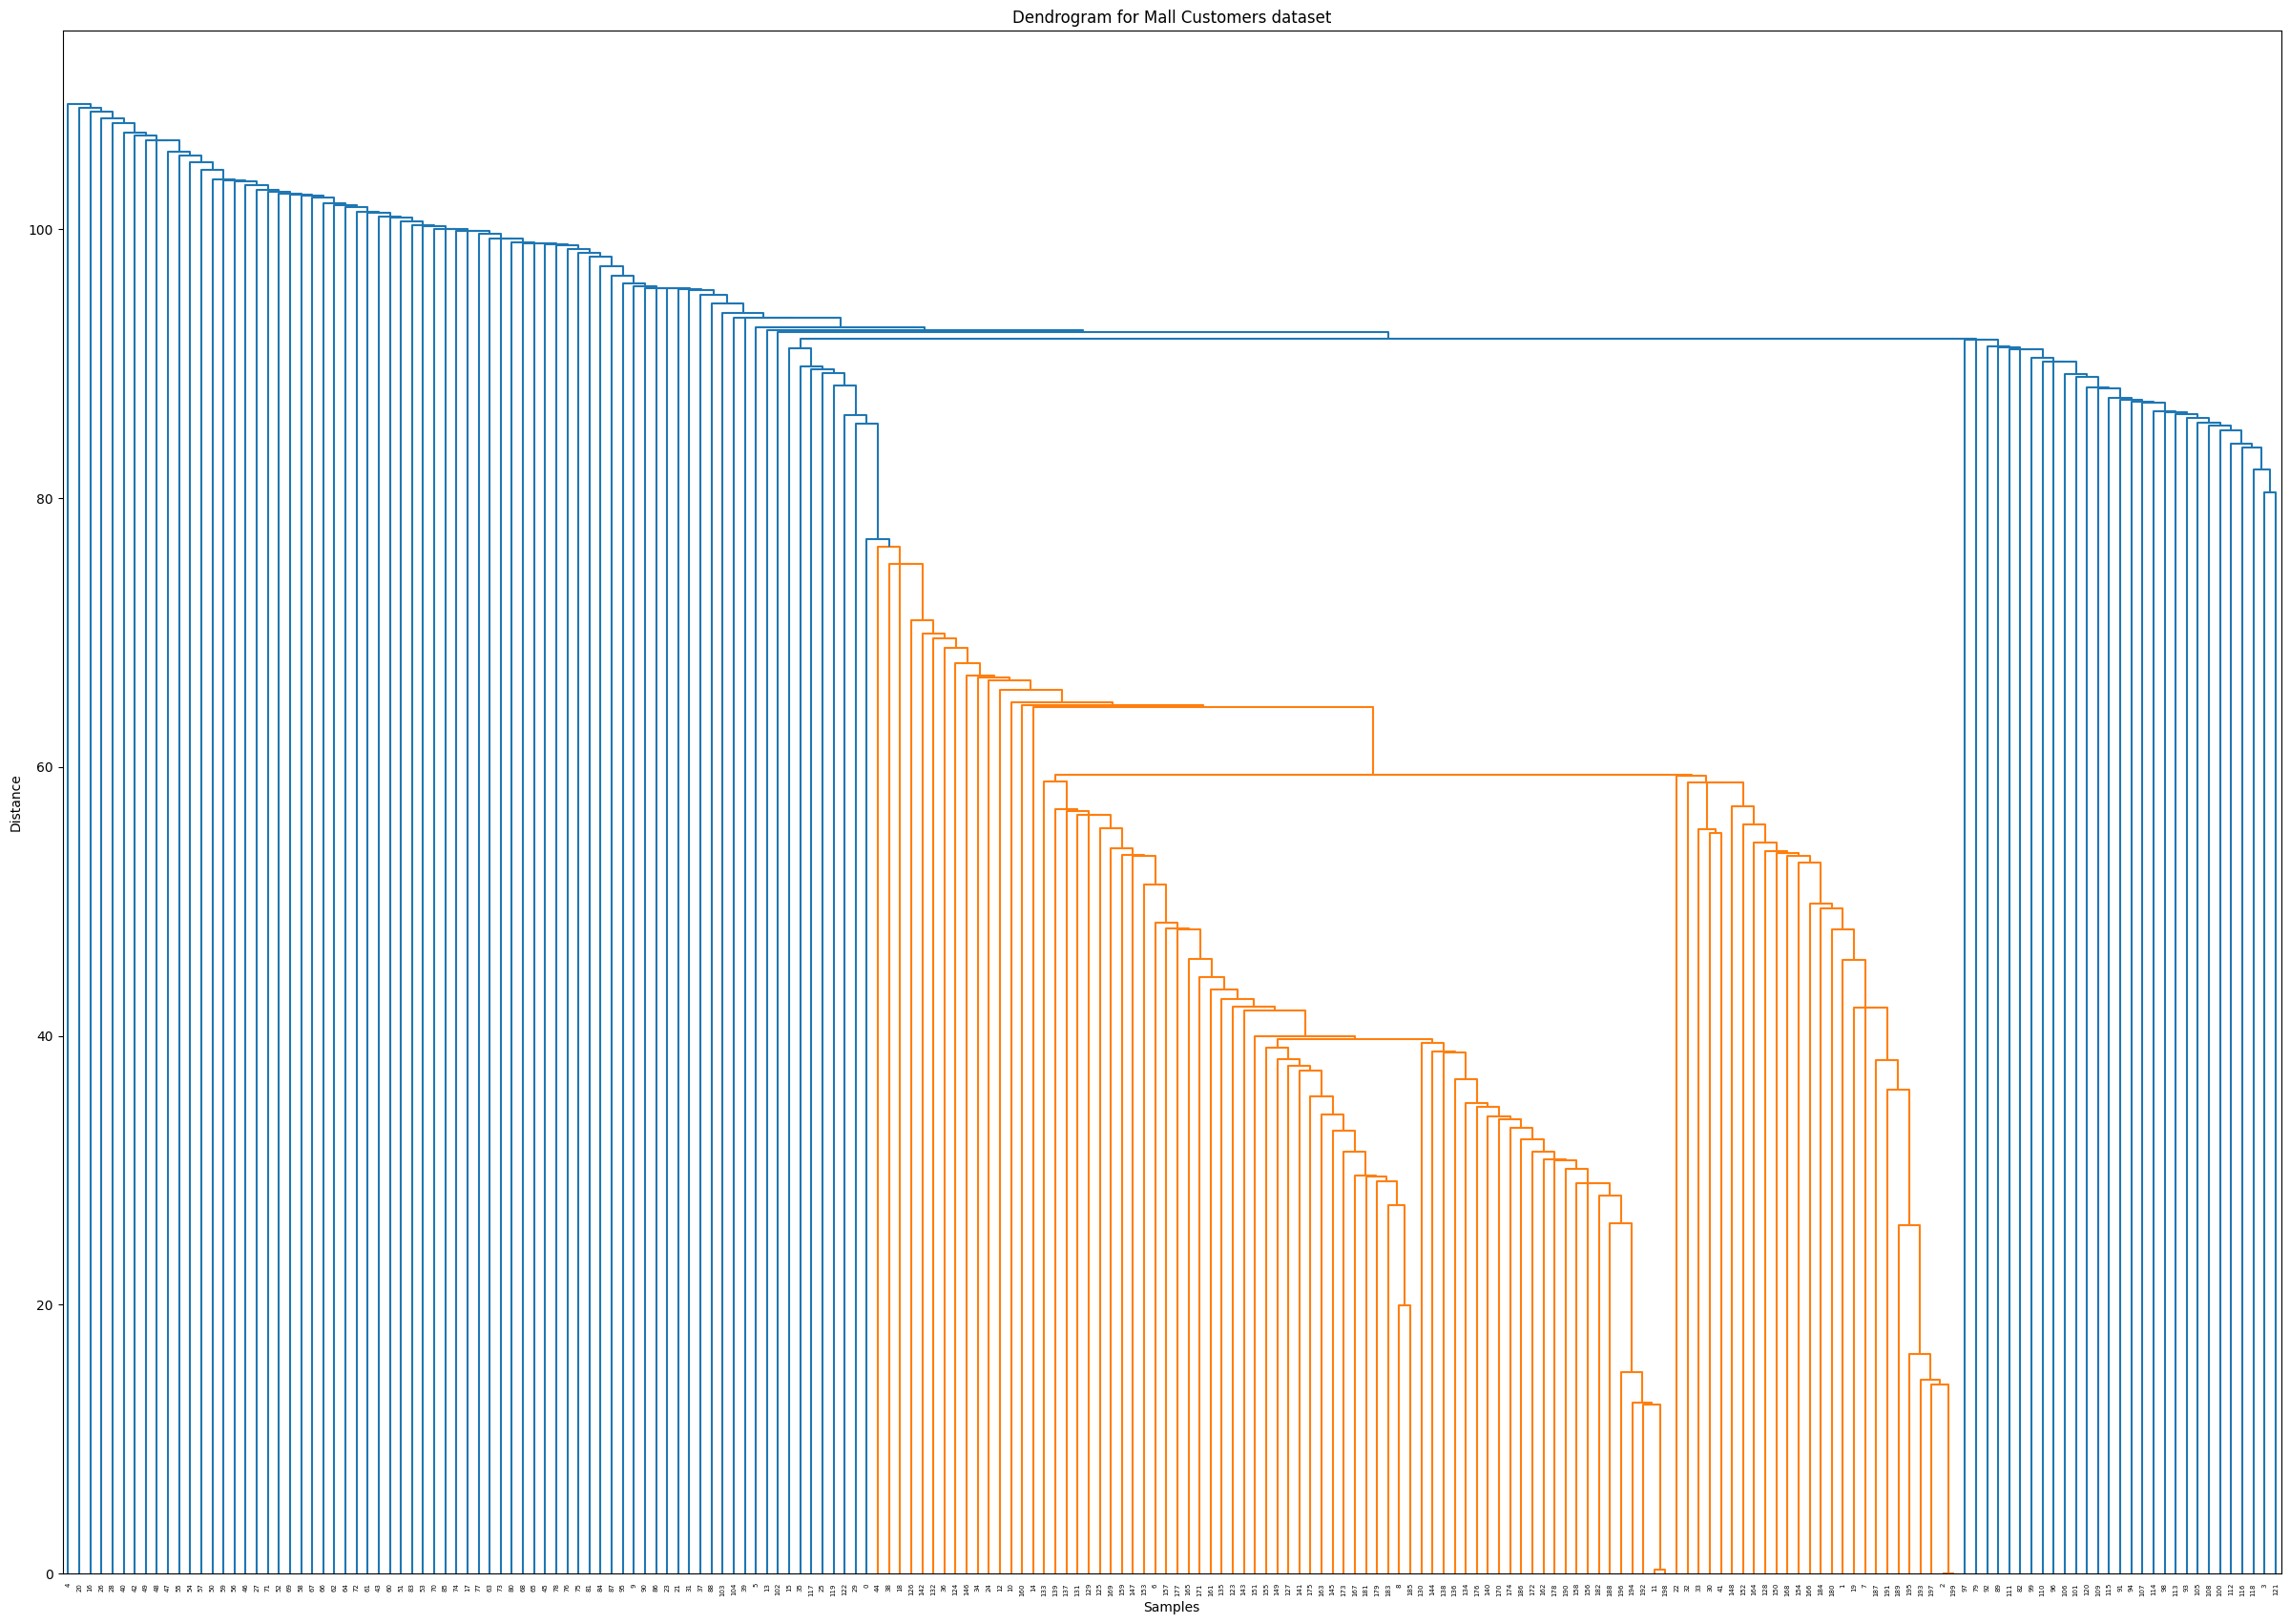

In [57]:
data = pd.read_csv('Mall_Customers.csv')
X = data[['Annual Income (k$)', 'Spending Score (1-100)']].values

similarity_matrix = euclidean_distances(X)

result_mall = Algo1_single_linkage(S=similarity_matrix, linkage='average')

plot_dendrogram(convertToScypi(result_mall, similarity_matrix.shape[0], np.max(similarity_matrix)),
                 fig_size=(30,21),
                 title='Dendrogram for Mall Customers dataset',
                 save_as_png=True)

Test with Gene Expression Cancer RNA-Seq dataset (from [Kaggle](https://www.kaggle.com/datasets/waalbannyantudre/gene-expression-cancer-rna-seq-donated-on-682016?select=data.csv))

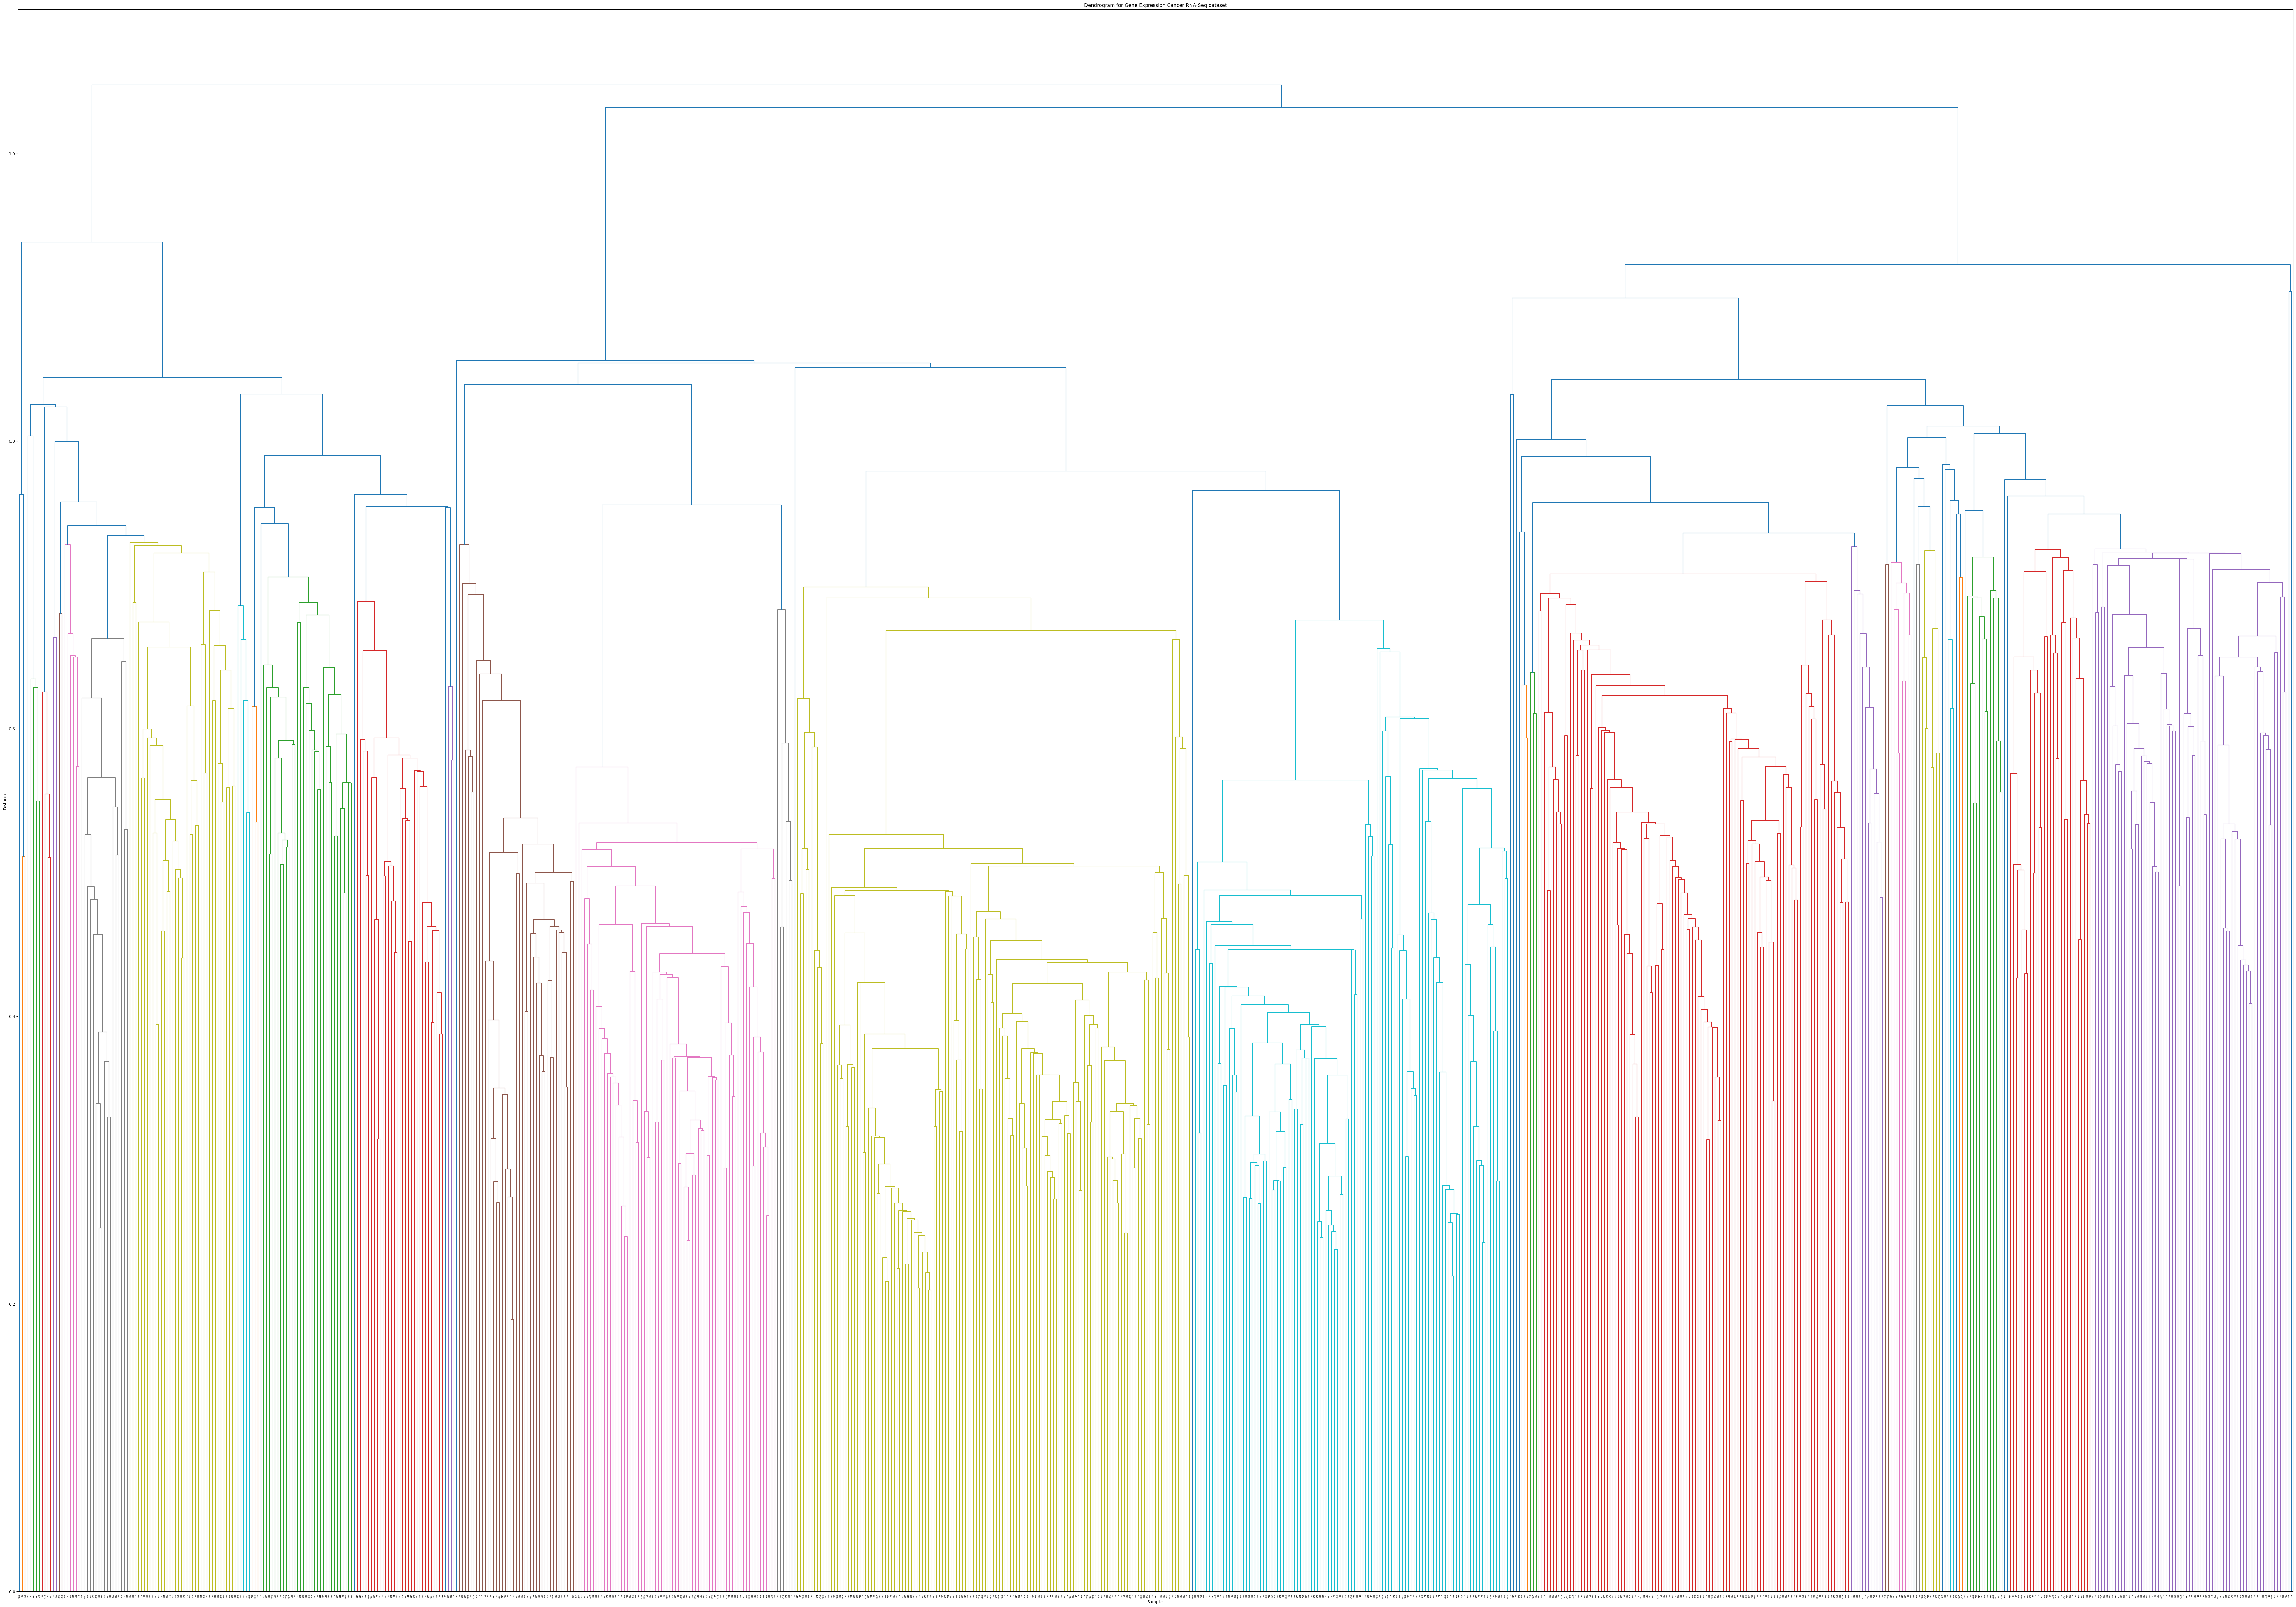

In [58]:
path = kagglehub.dataset_download("waalbannyantudre/gene-expression-cancer-rna-seq-donated-on-682016")

data = pd.read_csv(path + '/data.csv')
data_scaled = StandardScaler().fit_transform(data.iloc[:, 1:])
similarity_matrix = cosine_similarity(data_scaled)

result_rnaseq = Algo1_single_linkage(S=similarity_matrix, linkage='average')

Z = convertToScypi(result_rnaseq, similarity_matrix.shape[0], np.max(similarity_matrix))
plot_dendrogram(Z, fig_size=(100,70), title='Dendrogram for Gene Expression Cancer RNA-Seq dataset', save_as_png=True)

Some Gene Expression Cancer RNA-Seq Dataset Clustering Visualizations, based on the optimal number of clusters determined by silhouette score

In [59]:
best_score = -1
best_k = -1
labels_gene = None
for k in range(2, 15):
    labels_gene = sch.fcluster(Z,t=k,criterion='maxclust')
    score = silhouette_score(data_scaled, labels_gene, metric='euclidean')
    if score > best_score:
        best_score = score
        best_k = k
print(f"Best number of clusters by silhouette score: {best_k} with score {best_score}")
labels_gene = sch.fcluster(
    convertToScypi(result_rnaseq, similarity_matrix.shape[0], np.max(similarity_matrix)),
    t=best_k,
    criterion='maxclust'
)

Best number of clusters by silhouette score: 3 with score 0.0672292295489636


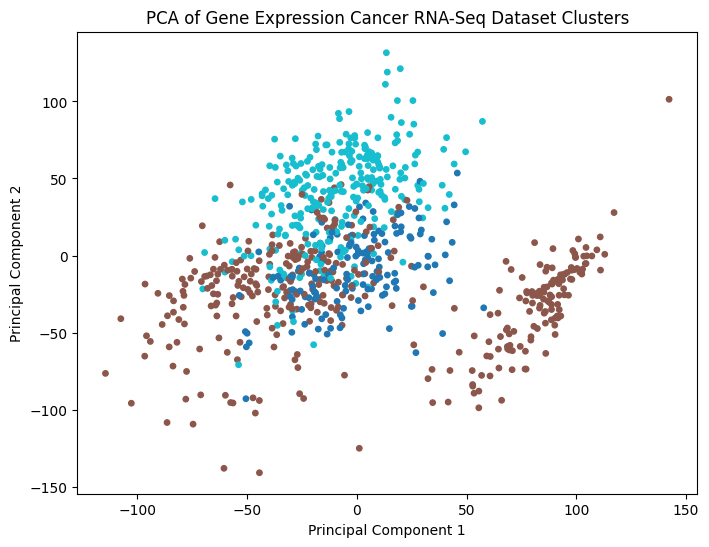

In [60]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(data_scaled)

plt.figure(figsize=(8,6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_gene, cmap='tab10', s=15)
plt.title('PCA of Gene Expression Cancer RNA-Seq Dataset Clusters')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()


Test with Gaia Stars Dataset from DR3 Data Release 3 (from [Kaggle](https://www.kaggle.com/datasets/realkiller69/gaia-stars-dataset-from-dr3-data-release-3))

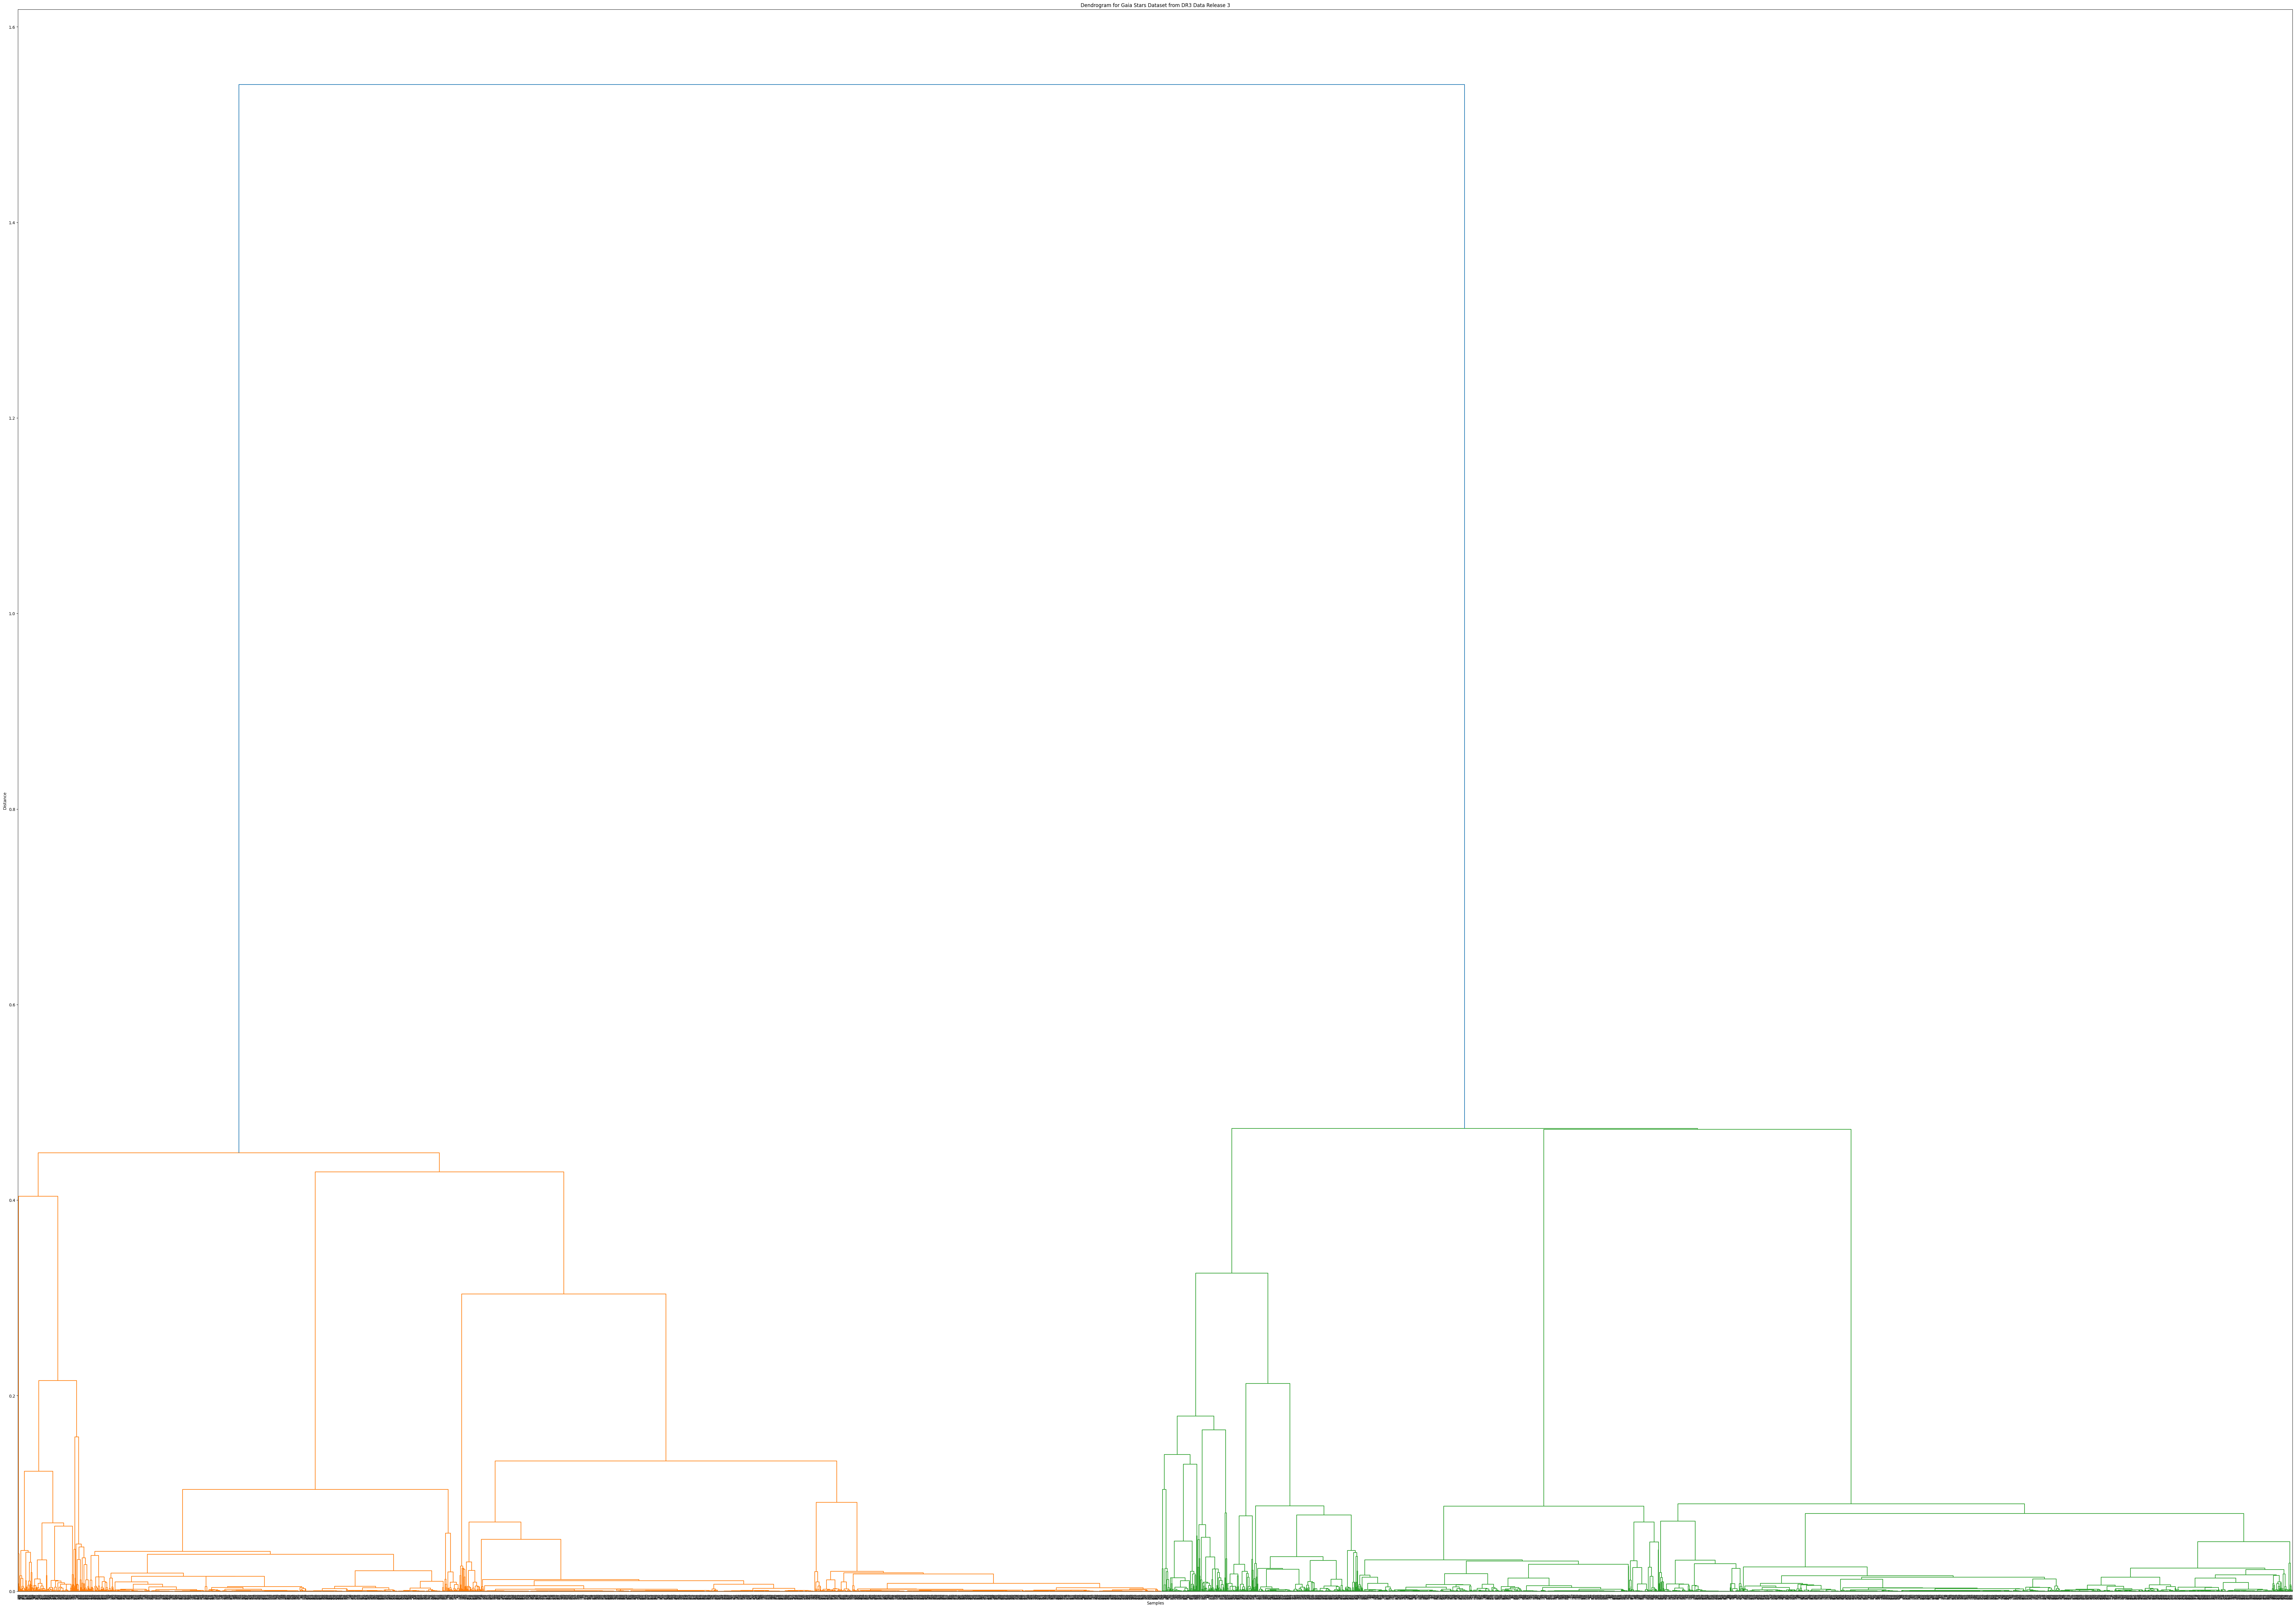

In [61]:
path = kagglehub.dataset_download("realkiller69/gaia-stars-dataset-from-dr3-data-release-3")

data = pd.read_csv(path + '/dataGaia2.csv')

features = ['Teff', 'Lum-Flame', '[Fe/H]'] # Selecting relevant features for clustering main sequence stars
data_clean = data[features].dropna()
data_clean = data_clean.iloc[:5000, :]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_clean)

similarity_matrix = cosine_similarity(X_scaled)

result_gaia = Algo1_single_linkage(S=similarity_matrix, linkage='average')

Z = convertToScypi(result_gaia, similarity_matrix.shape[0], np.max(similarity_matrix))
plot_dendrogram(Z, fig_size=(100,70), title='Dendrogram for Gaia Stars Dataset from DR3 Data Release 3', save_as_png=True)

Some Gaia Stars Dataset Clustering Visualizations, based on the optimal number of clusters determined by silhouette score

In [70]:
best_score = -1
best_k = -1
labels_gaia = None
for k in range(2, 15):
    labels_gaia = sch.fcluster(Z, t=k, criterion='maxclust' )
    score = silhouette_score(X_scaled, labels_gaia, metric='euclidean')
    if score > best_score:
        best_score = score
        best_k = k

print(f"Best number of clusters by silhouette score: {best_k} with score {best_score}")
labels_gaia = sch.fcluster(
    convertToScypi(result_gaia, similarity_matrix.shape[0], np.max(similarity_matrix)),
    t=best_k,
    criterion='maxclust'
)

Best number of clusters by silhouette score: 4 with score 0.4632289050242649


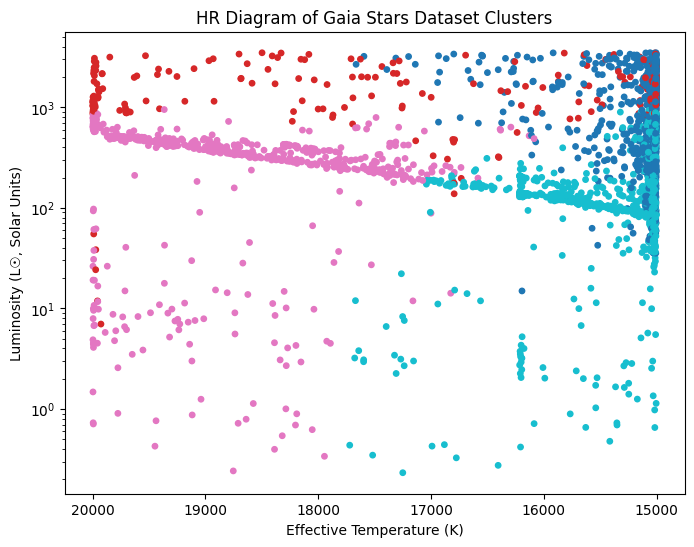

In [71]:
plt.figure(figsize=(8,6))
plt.scatter(
    data_clean['Teff'],
    data_clean['Lum-Flame'],
    c=labels_gaia,
    cmap='tab10',
    s=15
)
plt.gca().invert_xaxis()
plt.yscale('log')
plt.xlabel('Effective Temperature (K)')
plt.ylabel('Luminosity (L☉, Solar Units)')
plt.title('HR Diagram of Gaia Stars Dataset Clusters')
plt.show()


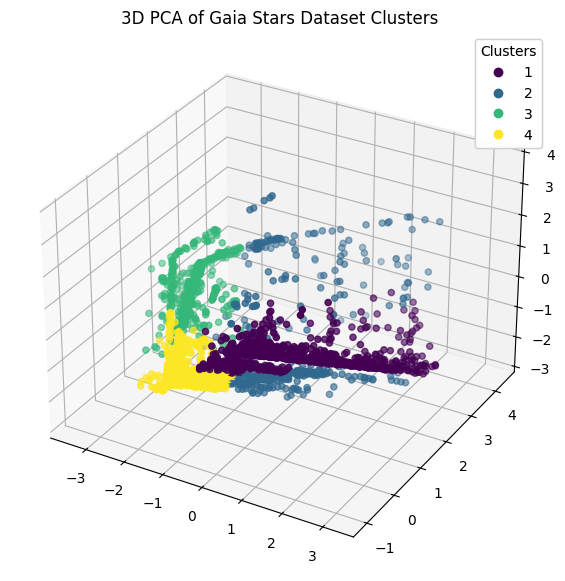

In [72]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=labels_gaia, cmap='viridis')
legend1 = ax.legend(*scatter.legend_elements(), title="Clusters")
ax.add_artist(legend1)
ax.set_title('3D PCA of Gaia Stars Dataset Clusters')
plt.show()